# Guía Básica para Mesa: Introducción y Simulación de Movimiento Aleatorio de un Agente

# Movimiento Continuo - Sin obstáculos

Dando continuidad a la guía anterior, esta vez consideramos el movimiento contínuo para un agente.

## Ejemplo: **Caminata Aleatoria**

Para introducir los conceptos, vamos a simular la caminata aleatoria de un agente en un espacio continuo. La caminata aleatoria de un agente tiene diversas aplicaciones en campos como la biología (modelando el movimiento de animales), la física (movimiento browniano), la economía (simulando precios de acciones) y la informática (optimización de algoritmos). También se utiliza en la teoría de redes y en el análisis de fenómenos sociales [[Random walk](https://en.wikipedia.org/wiki/Random_walk)].

## Implementación en Python

Instalamos mesa en Colab

In [88]:
%pip install mesa --quiet

/Users/oh/World/External/Study/UR/IAPS-I/.venv/bin/python: No module named pip
Note: you may need to restart the kernel to use updated packages.


Este código funciona para la versión 3.2.0 de mesa

In [89]:
import mesa
print(mesa.__version__)

3.5.1


Importo librerías

In [90]:
import random
import matplotlib.pyplot as plt
from matplotlib.animation import FuncAnimation # hacer la animación
from matplotlib.collections import LineCollection # estela con estilos por segmento
from IPython.display import HTML # Mostrar la animación como panel interactivo
from mesa import Agent, Model
from mesa.space import MultiGrid
from mesa.space import ContinuousSpace

Defino las clases para el agente y el modelo

In [91]:
# 1. Definición del agente
class ContinuousWalker(Agent):
    def __init__(self, model):
        super().__init__( model)
        # Posición inicial en el centro
        self.x = model.space.width / 2
        self.y = model.space.height / 2

    def move(self):
        # Movimiento aleatorio en el espacio continuo
        self.x += random.uniform(-1, 1)  # Movimiento en x
        self.y += random.uniform(-1, 1)  # Movimiento en y
        # Mantener al agente dentro de los límites
        ϵ = 1e-8
        # self.x = max(0 + ϵ, min(self.x, self.model.space.width - ϵ))
        # self.y = max(0 + ϵ, min(self.y, self.model.space.height - ϵ))
        self.x %= self.model.space.width
        self.y %= self.model.space.height
        self.model.space.move_agent(self, (self.x, self.y))  # Actualiza posición en el espacio de Mesa

# 2. Definición del modelo
class ContinuousModel(Model):
    def __init__(self, width, height, num_steps):
        super().__init__()
        self.num_agents = 1
        self.space = ContinuousSpace(width, height, torus=True)  # Toro: el agente da la vuelta al cruzar el borde
        self.num_steps = num_steps

        # Crear y colocar el agente en el espacio
        agent = ContinuousWalker( model=self)
        self.agents.add(agent)
        self.space.place_agent(agent, (agent.x, agent.y))

    def step(self):
        self.agents.shuffle_do("move")

Experimento inicial

Vamos a generar resultados utilizables de diferentes maneras.
1. Gráfica de la trayectoria recorrida en el espacio: los saltos por el borde del toro se dibujan punteados.
2. Animación interactiva del recorrido, con un panel de controles (play, pausa y deslizador) como en la guía anterior.


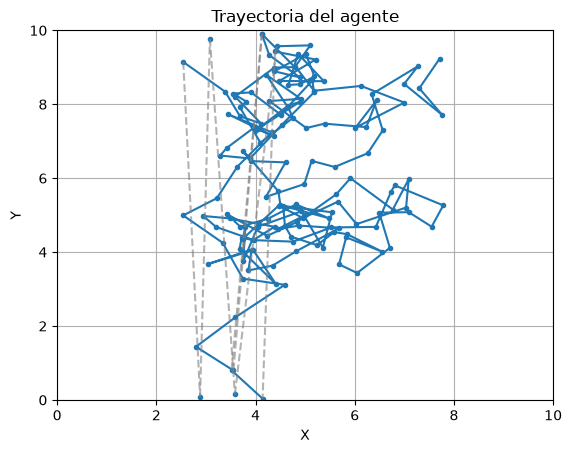

In [92]:
# 3. Configuración para visualización con matplotlib
num_steps = 150  # Número de pasos: con suficientes pasos el agente cruza los bordes del toro
model = ContinuousModel(10, 10, num_steps)

# Ejecutar el modelo y recolectar posiciones
agent = list(model.agents)[0]
positions = [(agent.x, agent.y)]  # Lista de posiciones para visualización
for _ in range(num_steps):
    model.step()
    positions.append((agent.x, agent.y))

# Detectar saltos por el borde del toro: si el salto es mayor a la mitad del espacio, cruzó de lado a lado
W, H = model.space.width, model.space.height
solid = [[positions[0]]]   # Tramos normales (línea continua)
wrapped = []               # Pares de puntos que cruzan el borde
for prev, curr in zip(positions, positions[1:]):
    if abs(curr[0] - prev[0]) > W / 2 or abs(curr[1] - prev[1]) > H / 2:
        wrapped.append((prev, curr))
        solid.append([curr])  # Cortar la línea continua
    else:
        solid[-1].append(curr)

for seg in solid:
    xs, ys = zip(*seg)
    plt.plot(xs, ys, '-o', markersize=3, color='C0')
for (x0, y0), (x1, y1) in wrapped:  # Saltos por el borde: punteados
    plt.plot([x0, x1], [y0, y1], '--', color='gray', alpha=0.6)

plt.xlim(0, W)
plt.ylim(0, H)
plt.grid(True)
plt.xlabel("X")
plt.ylabel("Y")
plt.title("Trayectoria del agente")
plt.show()

In [93]:
# Animación interactiva de la caminata: panel con play, pausa y deslizador
W, H = model.space.width, model.space.height

fig, ax = plt.subplots()
ax.set_xlim(0, W)
ax.set_ylim(0, H)
ax.set_title("Caminata Aleatoria: 1 agente", color="orange", fontweight="bold", size=15)
line, = ax.plot([], [], marker="o", color="b", markersize=5)  # Punto actual
trail = LineCollection([], linewidths=1.5)  # Estela
ax.add_collection(trail)

def update_trail(pts):
    # Estela: continua en tramos normales, punteada si el agente cruzó el borde (toro)
    segments, styles, colors = [], [], []
    for p, q in zip(pts[:-1], pts[1:]):
        cruza_borde = abs(q[0] - p[0]) > W / 2 or abs(q[1] - p[1]) > H / 2
        segments.append([p, q])
        styles.append((0, (4, 4)) if cruza_borde else "solid")
        colors.append("gray" if cruza_borde else "lightgray")
    trail.set_segments(segments)
    trail.set_linestyle(styles)
    trail.set_color(colors)

def animate(i):
    pts = positions[:i + 1]
    line.set_data([pts[-1][0]], [pts[-1][1]])
    update_trail(pts)
    return line, trail

plt.rcParams["animation.embed_limit"] = 60  # MB permitidos de animación embebida
anim = FuncAnimation(fig, animate, frames=len(positions), interval=300, blit=True)
plt.close(fig)  # la figura vive dentro del panel interactivo
HTML(anim.to_jshtml())

El panel interactivo tiene play, pausa y un deslizador: la gracia es pararse en un paso concreto y ver dónde cruzó el borde (tramo punteado). Ya no se genera ningún archivo de video: la animación vive dentro del cuaderno.


# Agente moviéndose en una región con obstáculos

Para añadir obstáculos en un espacio continuo en una simulación con la librería Mesa, podemos definir una clase de agente que se mueva aleatoriamente y detectar si la posición a la que desea moverse está ocupada por un obstáculo. Aquí tienes un ejemplo con obstáculos rectangulares en un espacio continuo. El agente se moverá aleatoriamente y cambiará de dirección si intenta moverse hacia un obstáculo.



## Implementación en Python

In [94]:
import random
import matplotlib.pyplot as plt
from matplotlib.animation import FuncAnimation
from mesa import Agent, Model
from mesa.space import ContinuousSpace
import numpy as np

In [95]:
# 1. Definición del agente
class ObstacleAvoidingAgent(Agent):
    def __init__(self, model):
        super().__init__(model)
        # Usamos self.random para inicializar la posición
        self.position = np.array([
            self.random.uniform(0, model.space.width),
            self.random.uniform(0, model.space.height)
        ])
        self.step_size = 1  # Tamaño del paso

    def move(self):
        # Movimiento aleatorio continuo usando self.random
        direction = np.array([
            self.random.uniform(-1, 1),
            self.random.uniform(-1, 1)
        ])
        new_position = self.position + direction * self.step_size

        # Evitar obstáculos
        collision = False
        for obstacle in self.model.obstacles:
            (x_min, y_min), (x_max, y_max) = obstacle
            if x_min <= new_position[0] <= x_max and y_min <= new_position[1] <= y_max:
                collision = True
                break

        # Actualizar posición si no hay colisión y está dentro de los límites
        if not collision and 0 <= new_position[0] <= self.model.space.width and 0 <= new_position[1] <= self.model.space.height:
            self.position = new_position
            self.model.space.move_agent(self, self.position)  # Actualizar posición en el espacio

# 2. Definición del modelo
class ObstacleModel(Model):
    def __init__(self, width, height, num_agents):
        super().__init__()
        self.space = ContinuousSpace(width, height, torus=False)
        self.obstacles = [((1, 1), (5, 5)), ((6, 6), (9, 9))]  # Obstáculos como rectángulos

        # Crear agentes
        for _ in range(num_agents):
            agent = ObstacleAvoidingAgent(self)
            self.space.place_agent(agent, agent.position)  # Añade el agente al espacio

    def step(self):
        self.agents.shuffle_do("move")



In [96]:
model = ObstacleModel(10, 10, 1)
positions = [model.agents[0].position.copy()]

In [97]:
# 3. Animación interactiva del agente evitando obstáculos
model = ObstacleModel(10, 10, 1)
num_steps = 50
positions = [model.agents[0].position.copy()]  # Inicializar la lista de posiciones
for _ in range(num_steps):
    model.step()
    positions.append(model.agents[0].position.copy())

fig, ax = plt.subplots()
ax.set_xlim(0, model.space.width)
ax.set_ylim(0, model.space.height)
ax.set_title("Agente evadiendo obstáculos", color="orange", fontweight="bold", size=15)

# Dibujar obstáculos solo una vez
for (x_min, y_min), (x_max, y_max) in model.obstacles:
    rect = plt.Rectangle((x_min, y_min), x_max - x_min, y_max - y_min, color="gray", alpha=0.5)
    ax.add_patch(rect)

agent_dot, = ax.plot([], [], "bo", markersize=5)  # Punto del agente
trail_line, = ax.plot([], [], "b-", alpha=0.5)  # Línea de la trayectoria

def init():
    agent_dot.set_data([], [])
    trail_line.set_data([], [])
    return agent_dot, trail_line

def update(frame):
    x, y = positions[frame]
    agent_dot.set_data([x], [y])
    x_trail, y_trail = zip(*positions[:frame + 1])
    trail_line.set_data(x_trail, y_trail)
    return agent_dot, trail_line

plt.rcParams["animation.embed_limit"] = 60  # MB permitidos de animación embebida
anim = FuncAnimation(fig, update, init_func=init, frames=len(positions), interval=200, blit=True)
plt.close(fig)  # la figura vive dentro del panel interactivo
HTML(anim.to_jshtml())

**Ejercicio:**

1. Evitar que la posición inicial esté dentro de un obstáculo.
2. Modelar la dinámica de la caminata aleatoria de múltiples agentes.

# Conclusión:


En esta segunda guía, se ha explorado el movimiento de un agente en un espacio continuo, tanto con como sin obstáculos. A través de la implementación de un modelo basado en agentes utilizando la biblioteca Mesa, hemos podido simular un comportamiento realista en entornos donde la navegación y la evasión de obstáculos son cruciales.

**Aspectos Destacados:**
- **Movimiento Aleatorio:** El agente se mueve de manera aleatoria, lo que refleja un comportamiento exploratorio. Este enfoque puede ser útil en simulaciones que requieren análisis de patrones de movimiento, como en el estudio de la dispersión de especies o la exploración de espacios desconocidos.
- **Evasión de Obstáculos:** La capacidad del agente para evitar obstáculos introduce una dimensión adicional al modelo, lo que lo hace más aplicable a situaciones del mundo real, como la navegación de vehículos autónomos, robots en entornos no estructurados, o simulaciones de tráfico.

**Posibles Aplicaciones:**
1. **Robótica:** La simulación de agentes que evitan obstáculos es fundamental para el desarrollo de robots autónomos que operan en entornos dinámicos, como drones de entrega o vehículos autónomos.
2. **Modelado de Tráfico:** Los principios de este modelo pueden aplicarse para entender cómo los vehículos o peatones interactúan con su entorno y evitan obstáculos en un entorno urbano.
3. **Ecología:** En estudios de ecología, se pueden modelar las trayectorias de animales que navegan en su hábitat, considerando la presencia de obstáculos naturales.
4. **Simulaciones de Juegos:** En el diseño de videojuegos, los NPC (personajes no jugables) pueden beneficiarse de este tipo de comportamiento para crear interacciones más dinámicas y realistas.
5. **Optimización de Rutas:** Las técnicas de evasión de obstáculos pueden utilizarse en la optimización de rutas para logística y transporte, mejorando la eficiencia en la entrega de bienes.

En resumen, este modelo de movimiento en un espacio continuo no solo proporciona una comprensión más profunda de los comportamientos de los agentes, sino que también abre la puerta a una variedad de aplicaciones prácticas en diversos campos. La capacidad de simular y analizar el movimiento en entornos complejos es un paso importante hacia la implementación de soluciones tecnológicas que imiten comportamientos naturales y mejoren la interacción con el entorno.

[Nicolás Avilán Vargas, Ph.D.](https://www.linkedin.com/in/nicoavilanv)

Si encuentra algún error o tiene una sugerencia de mejora, por favor escríbame a nicolasg.avilan@urosario.edu.co.